# 05 · Next-day PM10 forecast

**Task:** at the end of day *t*, predict the city-average PM10 for day *t + 1*.

**Honest evaluation:**
- **Time-based split, no shuffling.** Train on 2015–2022, choose the model on 2023 (validation), and evaluate **once** on 2024–2025 (test). 2026 (provisional data) is an extra out-of-sample check.
- **No leakage.** Features for day *t* use only data available by the end of day *t* (unit-tested in `tests/test_features.py`).
- **Always compare with a naive baseline.** "Tomorrow = today" (*persistence*) is hard to beat for air pollution, because air masses change slowly. A model is only useful if it beats this.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from src.config import DATA_PROCESSED, UNIT, EU_PM10_DAILY_LIMIT
from src.features import make_features, time_split, regression_metrics, TARGET
from src.plotting import set_style, add_source, save, COLORS, GREY, LIGHT_GREY
set_style()

city = pd.read_parquet(DATA_PROCESSED / "daily_city.parquet")
feat = make_features(city)
# Keep days where both today's and tomorrow's PM10 exist, so every model is scored on the same days.
feat = feat[feat[TARGET].notna() & feat["pm10_lag0"].notna()]
FEATURES = [c for c in feat.columns if c != TARGET]
train, valid, test_all = time_split(feat, "2023-01-01", "2024-01-01")
test = test_all[test_all.index < "2026-01-01"]
extra_2026 = test_all[test_all.index >= "2026-01-01"]
print({k: len(v) for k, v in {"train 2015-22": train, "valid 2023": valid, "test 2024-25": test, "extra 2026": extra_2026}.items()})
FEATURES

{'train 2015-22': 2894, 'valid 2023': 363, 'test 2024-25': 716, 'extra 2026': 316}


['pm10_lag0',
 'pm10_lag1',
 'pm10_lag2',
 'pm10_lag6',
 'pm25_lag0',
 'no2_lag0',
 'no2_lag1',
 'pm10_mean3',
 'pm10_mean7',
 'pm10_change1',
 'doy_sin',
 'doy_cos',
 'target_dow',
 'target_is_sunday']

**Features** (all known at the end of day *t*): PM10 today, yesterday, 2 days ago and 6 days ago; 3- and 7-day PM10 averages and today's change; today's PM2.5; NO2 today and yesterday; the target day's season (`doy_sin`, `doy_cos`, a circular encoding so 31 Dec and 1 Jan are close) and day of the week.

**What is missing:** weather forecasts (wind, rain, mixing height) are the main driver of day-to-day changes, and we do not use them. This is the biggest limitation of this model.

## Model options

1. **Naive persistence:** ŷ(t+1) = PM10(t).
2. **Linear regression** on the same features (missing values filled with the training mean).
3. **LightGBM, level target:** predict PM10(t+1) directly.
4. **LightGBM, log-ratio target:** predict log(PM10(t+1) / PM10(t)), then convert back with ŷ = PM10(t) · exp(prediction). This predicts the *relative change* from today. It cannot be biased by the fact that the training years were dirtier than the test years, because it learns changes, not levels.

LightGBM (gradient boosted decision trees) builds many small trees, each correcting the errors of the previous ones. It handles non-linear effects and interactions (e.g. "high today *and* winter *and* weekday") and missing values natively. We use fixed, moderate hyperparameters, with no large tuning search that could overfit the validation year.

In [2]:
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1)

def fit_predict(kind, tr, te):
    """Fit model `kind` on `tr` and return predictions of PM10(t+1) for `te`."""
    if kind == "Naive (tomorrow = today)":
        return te["pm10_lag0"].values
    if kind == "Linear regression":
        fill = tr[FEATURES].mean()
        m = LinearRegression().fit(tr[FEATURES].fillna(fill), tr[TARGET])
        return m.predict(te[FEATURES].fillna(fill))
    if kind == "LightGBM (level)":
        return lgb.LGBMRegressor(**LGB_PARAMS).fit(tr[FEATURES], tr[TARGET]).predict(te[FEATURES])
    if kind == "LightGBM (log-ratio)":
        y = np.log(tr[TARGET] / tr["pm10_lag0"])
        m = lgb.LGBMRegressor(**LGB_PARAMS).fit(tr[FEATURES], y)
        return te["pm10_lag0"].values * np.exp(m.predict(te[FEATURES]))
    raise ValueError(kind)

MODELS = ["Naive (tomorrow = today)", "Linear regression", "LightGBM (level)", "LightGBM (log-ratio)"]

## Model selection (training years + validation year only)

**Expanding-window cross-validation by calendar year:** for each year from 2019 to 2022, train on all earlier years and test on that year. Then also score on 2023, training on 2015–2022. That gives five honest "train on the past, predict the future" folds. The test set (2024–2025) is not touched here.

In [3]:
rows = []
for year in [2019, 2020, 2021, 2022]:
    tr, te = train[train.index.year < year], train[train.index.year == year]
    for kind in MODELS:
        rows.append({"fold": f"CV {year}", "model": kind, **regression_metrics(te[TARGET], fit_predict(kind, tr, te))})
for kind in MODELS:
    rows.append({"fold": "valid 2023", "model": kind, **regression_metrics(valid[TARGET], fit_predict(kind, train, valid))})
sel = pd.DataFrame(rows)
sel.pivot(index="model", columns="fold", values="MAE").loc[MODELS].round(2)

fold,CV 2019,CV 2020,CV 2021,CV 2022,valid 2023
model,,,,,
Naive (tomorrow = today),9.41,8.75,8.28,8.07,7.21
Linear regression,8.63,7.82,7.79,7.26,6.54
LightGBM (level),8.53,8.16,7.86,7.49,6.58
LightGBM (log-ratio),8.55,8.84,7.93,7.62,6.41


In [4]:
summary_sel = sel.groupby("model")[["MAE", "RMSE", "bias"]].mean().loc[MODELS]
summary_sel["MAE skill vs naive %"] = 100 * (1 - summary_sel["MAE"] / summary_sel.loc[MODELS[0], "MAE"])
summary_sel.round(2)

,MAE,RMSE,bias,MAE skill vs naive %
model,,,,
Naive (tomorrow = today),8.34,12.03,0.05,0.00
Linear regression,7.61,10.78,-0.44,8.83
LightGBM (level),7.73,10.99,0.12,7.42
LightGBM (log-ratio),7.87,11.13,-1.46,5.72


**Choice:** we select the model with the lowest average MAE across the five selection folds. MAE (mean absolute error) is the average size of the error in µg/m³, easy to explain and not dominated by a few extreme days. RMSE punishes large errors more and is reported too.

In [5]:
best = summary_sel.drop(MODELS[0])["MAE"].idxmin()
print("Selected model:", best)

Selected model: Linear regression


## Final evaluation on the test set (2024–2025), done once

Retrain every model on 2015–2023 and predict 2024–2025.

In [6]:
train_full = pd.concat([train, valid])
preds = pd.DataFrame({k: fit_predict(k, train_full, test) for k in MODELS}, index=test.index)
res = pd.DataFrame({k: regression_metrics(test[TARGET], preds[k]) for k in MODELS}).T
res["MAE skill vs naive %"] = 100 * (1 - res["MAE"] / res.loc[MODELS[0], "MAE"])
res.round(2)

,MAE,RMSE,bias,MAE skill vs naive %
Naive (tomorrow = today),7.91,12.75,-0.14,0.00
Linear regression,7.21,11.71,-0.24,8.91
LightGBM (level),7.32,11.75,0.28,7.49
LightGBM (log-ratio),7.18,11.83,-1.22,9.23


### Is the improvement real, or luck? A bootstrap check

We resample the 2024–2025 test days (in blocks of 7 days, so that correlated neighbouring days stay together) 2,000 times and recompute the MAE difference between the selected model and naive.

In [7]:
rng = np.random.default_rng(0)
abs_err_naive = np.abs(preds[MODELS[0]] - test[TARGET]).values
abs_err_best = np.abs(preds[best] - test[TARGET]).values
n, block = len(test), 7
diffs = []
for _ in range(2000):
    starts = rng.integers(0, n - block, size=n // block + 1)
    idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
    diffs.append(abs_err_naive[idx].mean() - abs_err_best[idx].mean())
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"MAE improvement of '{best}' over naive: {abs_err_naive.mean() - abs_err_best.mean():.2f} µg/m³ (95% CI {lo:.2f} to {hi:.2f})")

MAE improvement of 'Linear regression' over naive: 0.71 µg/m³ (95% CI 0.33 to 1.09)


### Extra check on 2026 (provisional data)

Same models, still trained on 2015–2023, on the days of 2026 so far.

In [8]:
p26 = pd.DataFrame({k: fit_predict(k, train_full, extra_2026) for k in MODELS}, index=extra_2026.index)
r26 = pd.DataFrame({k: regression_metrics(extra_2026[TARGET], p26[k]) for k in MODELS}).T
r26["MAE skill vs naive %"] = 100 * (1 - r26["MAE"] / r26.loc[MODELS[0], "MAE"])
print(f"{len(extra_2026)} days, {extra_2026.index.min().date()} to {extra_2026.index.max().date()}")
r26.round(2)

316 days, 2026-01-01 to 2026-11-15


,MAE,RMSE,bias,MAE skill vs naive %
Naive (tomorrow = today),6.35,10.62,0.47,0.00
Linear regression,6.06,8.82,-0.08,4.54
LightGBM (level),5.73,8.00,0.59,9.77
LightGBM (log-ratio),5.97,9.04,-0.59,6.01


## Where does the model help, and where does it fail?

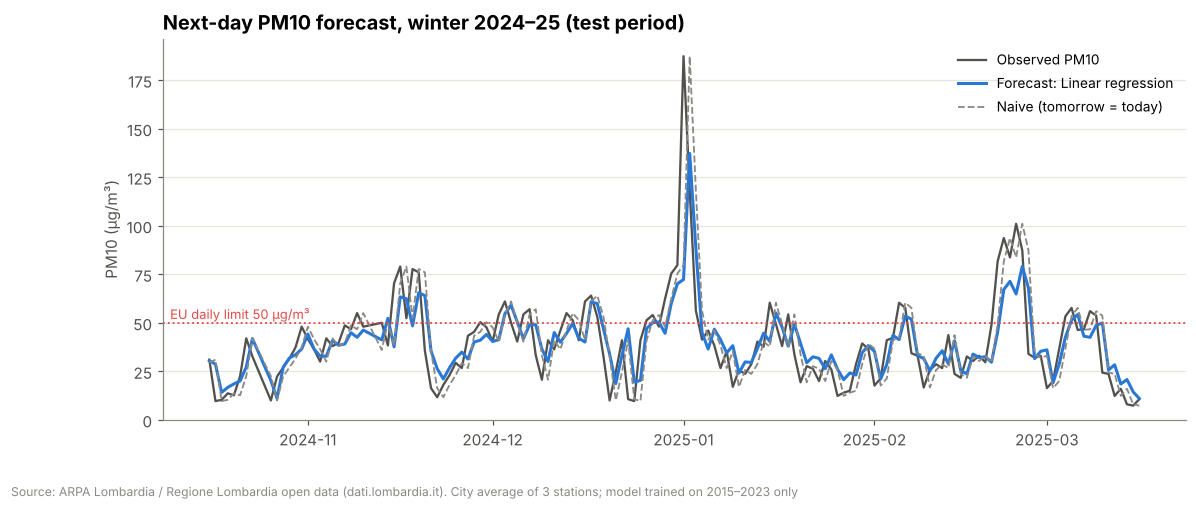

In [9]:
win = slice("2024-10-15", "2025-03-15")
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test.loc[win].index + pd.Timedelta(days=1), test.loc[win, TARGET], color=GREY, lw=1.5, label="Observed PM10")
ax.plot(preds.loc[win].index + pd.Timedelta(days=1), preds.loc[win, best], color=COLORS["PM10"], lw=2, label=f"Forecast: {best}")
ax.plot(preds.loc[win].index + pd.Timedelta(days=1), preds.loc[win, MODELS[0]], color=LIGHT_GREY, lw=1.2, ls="--", label="Naive (tomorrow = today)")
ax.axhline(EU_PM10_DAILY_LIMIT, color="#e34948", ls=":", lw=1.2)
ax.text(ax.get_xlim()[0], EU_PM10_DAILY_LIMIT + 2, f"  EU daily limit {EU_PM10_DAILY_LIMIT} {UNIT}", color="#e34948", fontsize=8.5)
ax.set_ylabel(f"PM10 ({UNIT})")
ax.set_ylim(0, None)
ax.set_title("Next-day PM10 forecast, winter 2024–25 (test period)")
ax.legend(loc="upper right", fontsize=9)
add_source(fig, "City average of 3 stations; model trained on 2015–2023 only")
save(fig, "09_forecast_winter")
plt.show()

In [10]:
err = preds.sub(test[TARGET], axis=0).abs()
by_season = err.groupby(np.where(test.index.month.isin([10, 11, 12, 1, 2, 3]), "Oct–Mar (cold)", "Apr–Sep (warm)")).mean()
by_season.round(2)

,Naive (tomorrow = today),Linear regression,LightGBM (level),LightGBM (log-ratio)
Apr–Sep (warm),4.50,4.21,4.22,4.12
Oct–Mar (cold),11.31,10.19,10.41,10.23


Errors are much larger in the cold season, when levels are higher and change fast with the weather. Both models struggle on days when a weather change (wind, rain, föhn) suddenly cleans the air or an inversion builds up. Without weather inputs this is expected.

### Can it warn about high-pollution days?

A practical use is predicting whether tomorrow will exceed the EU limit of 50 µg/m³.

In [11]:
actual_hi = test[TARGET] > EU_PM10_DAILY_LIMIT
rows = {}
for k in [MODELS[0], best]:
    pred_hi = preds[k] > EU_PM10_DAILY_LIMIT
    tp = int((pred_hi & actual_hi).sum()); fp = int((pred_hi & ~actual_hi).sum()); fn = int((~pred_hi & actual_hi).sum())
    rows[k] = {"exceedance days": int(actual_hi.sum()), "caught": tp, "missed": fn, "false alarms": fp,
               "recall %": 100 * tp / (tp + fn), "precision %": 100 * tp / (tp + fp)}
pd.DataFrame(rows).T.round(1)

,exceedance days,caught,missed,false alarms,recall %,precision %
Naive (tomorrow = today),76.0,46.0,30.0,29.0,60.5,61.3
Linear regression,76.0,41.0,35.0,14.0,53.9,74.5


### Which features matter?

The selected model may be linear, but the LightGBM (level) model's importances are easy to read, so we show them for interpretation. We also show the linear model's coefficients on standardised features (change in µg/m³ for a one-standard-deviation change in the feature).

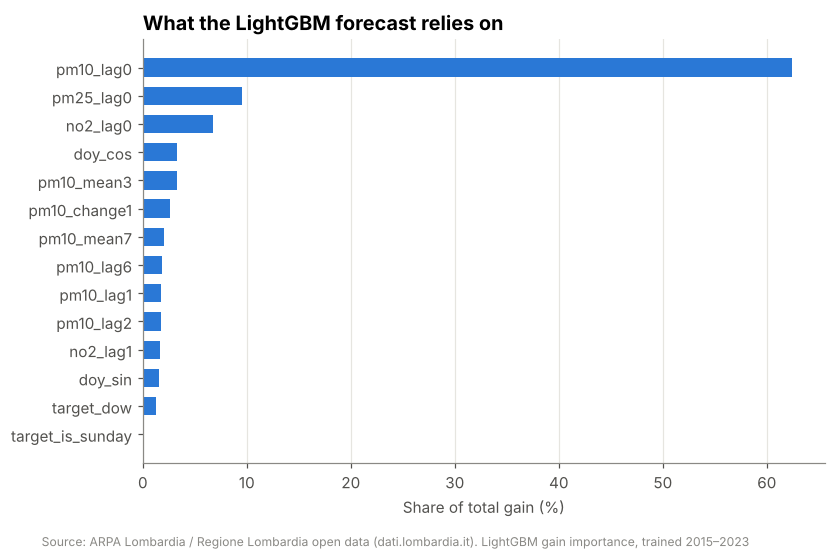

pm10_lag0       62.5
pm25_lag0        9.6
no2_lag0         6.7
doy_cos          3.3
pm10_mean3       3.3
pm10_change1     2.6
dtype: float64


pm10_lag0       15.28
pm10_lag1       -6.46
pm10_mean3       5.03
no2_lag0         4.21
pm10_lag2       -2.33
pm10_change1    -2.30
doy_cos          1.79
target_dow      -1.37
Name: µg/m³ per 1 SD, dtype: float64

In [12]:
if True:
    final = lgb.LGBMRegressor(**LGB_PARAMS, importance_type="gain").fit(train_full[FEATURES], train_full[TARGET])
    imp = pd.Series(final.feature_importances_, index=FEATURES).sort_values()
    imp = 100 * imp / imp.sum()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(imp.index, imp.values, color=COLORS["PM10"], height=0.65)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Share of total gain (%)")
    ax.set_title("What the LightGBM forecast relies on")
    add_source(fig, "LightGBM gain importance, trained 2015–2023")
    save(fig, "10_feature_importance")
    plt.show()
    print(imp.sort_values(ascending=False).round(1).head(6))

Xs = train_full[FEATURES].fillna(train_full[FEATURES].mean())
lin = LinearRegression().fit((Xs - Xs.mean()) / Xs.std(), train_full[TARGET])
pd.Series(lin.coef_, index=FEATURES).sort_values(key=abs, ascending=False).round(2).head(8).rename("µg/m³ per 1 SD")

Gain importance shows what the model *uses*, not what *causes* PM10. Correlated features (e.g. PM10 today and its 3-day mean) share credit in arbitrary ways, and the same applies to the linear coefficients: individual values should not be over-interpreted.

## Conclusions

- **Persistence is a strong baseline:** "tomorrow = today" has a test MAE of 7.9 µg/m³, because pollution episodes last several days.
- **The selected model (linear regression, chosen on the cross-validation folds plus 2023) beats it by 8.9% on the 2024–2025 test set:** MAE 7.21 vs 7.91 µg/m³. A block bootstrap gives a 95% interval of 0.33–1.09 µg/m³ for the improvement, so it is small but reliably above zero.
- **Gradient boosting did not beat the linear model.** On the test set the three models are within 0.15 µg/m³ of each other (LightGBM log-ratio 7.18, linear 7.21, LightGBM level 7.32), which is too small a difference to call a winner. With these features the signal is mostly linear: today's level, a pull back towards recent averages, and the season. On the provisional 2026 data LightGBM (level) did best (9.8% better than naive, vs 4.5% for linear), a reminder that rankings between close models change from year to year.
- **High-pollution warnings:** for days above 50 µg/m³ the model gives half as many false alarms as persistence (14 vs 29, precision 75% vs 61%) but misses more real exceedances (recall 54% vs 61%). Like most regression models, it smooths the extremes.
- **Main limitation: no weather data.** Errors in the cold season are about 2.4× those in the warm season, when weather changes drive sudden swings. Adding ARPA weather sensors or weather *forecasts* (wind, rain, boundary-layer height) is the obvious next step and would probably help more than any change of algorithm.